# TSJM Reproduction (Baghfalaki et al., 2026)

Python walkthrough of the **two-stage joint modeling** (TSJM) method for multiple longitudinal markers and a time-to-event outcome.

**Goal of this notebook:** reproduce only the pieces needed to show you understand the paper's workflow — not a full reimplementation of the R package.

| Step | Content |
|------|--------|
| 1 | Data setup (this cell block) |
| 2 | Model equations & code skeletons |
| 3 | Stage 1: one-marker joint model (one marker) |
| 4 | Stage 1 for all markers → predicted trajectories |
| 5 | Stage 2: Cox with time-dependent markers |
| 6 | (Optional) Rubin's rules for Stage-2 SEs |
| 7 | Dynamic prediction (Algorithm 1) |
| 8 | AUC / Brier score |

## Step 1 — Data setup

### What the paper/package need
TSJM always works with **two tables** that share the same subject `id`:

1. **Longitudinal (`dataLong`)** — one row per subject–visit–marker set  
   - `id`, `obstime` (visit time)  
   - markers `Y1`, `Y2`, …  
   - baseline covariates that appear in the LMM (here `x1`, `x2`)

2. **Survival (`dataSurv`)** — one row per subject  
   - `id`, `survtime` = $\min(T^*, C)$, `death` = $\delta$ (1 = event, 0 = censored)  
   - same baseline covariates used in the hazard model

### Dataset we use in Step 1
We use the **simulated data shipped with the TSJM R package** (`dataLong` / `dataSurv`).  
Same data as `Exam1.md` / `exampleTS.R`, so you can later compare Python numbers to the R examples.

> Paper §5.1 uses **PBC2** (5 biomarkers, death). Same *structure* as below; we can swap to PBC2 later for Table 3–style validation.

### What you should understand after Step 1
- Why long + surv must be kept separate
- That every `id` in survival must appear in longitudinal (and vice versa for subjects we analyze)
- Why we split **by subject**, not by row (train/valid)

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2)  # matches set.seed(2) spirit in the R examples

data_long = pd.read_csv("dataLong.csv")
data_surv = pd.read_csv("dataSurv.csv")

print("Longitudinal:", data_long.shape)
print("Survival:    ", data_surv.shape)
data_long.head()

Longitudinal: (6101, 8)
Survival:     (600, 5)


,obstime,id,x1,x2,Y1,Y2,Y3,Y4
0,0.00,1,1,0,0.390928,0.545231,-0.597284,-0.448971
1,0.05,1,1,0,-0.077782,0.795606,0.023423,-0.766830
2,0.10,1,1,0,0.257467,0.503275,-0.195009,-0.247606
3,0.15,1,1,0,0.128846,1.493444,-0.125590,-0.239593
4,0.20,1,1,0,0.561380,0.901875,-0.679880,-0.492348


In [15]:
data_surv.head()

,id,x1,x2,survtime,death
0,1,1,0,2.000000,0
1,2,1,1,1.552795,1
2,3,0,0,0.825177,0
3,4,1,0,0.129148,0
4,5,1,1,2.000000,0


### Sanity checks
Before modeling, confirm IDs align and get a feel for follow-up / event rate.

In [16]:
ids_long = set(data_long["id"].unique())
ids_surv = set(data_surv["id"].unique())

print(f"Subjects in long: {len(ids_long)}")
print(f"Subjects in surv: {len(ids_surv)}")
print(f"IDs only in long: {len(ids_long - ids_surv)}")
print(f"IDs only in surv: {len(ids_surv - ids_long)}")

print("\nEvent rate:", data_surv["death"].mean().round(3))
print("Visits per subject (describe):")
print(data_long.groupby("id").size().describe())

print("\nMarker columns:", [c for c in data_long.columns if c.startswith("Y")])
print("Covariates in surv:", [c for c in data_surv.columns if c.startswith("x")])

Subjects in long: 600
Subjects in surv: 600
IDs only in long: 0
IDs only in surv: 0

Event rate: 0.493
Visits per subject (describe):
count    600.000000
mean      10.168333
std       10.195256
min        1.000000
25%        3.000000
50%        7.000000
75%       14.000000
max       41.000000
dtype: float64

Marker columns: ['Y1', 'Y2', 'Y3', 'Y4']
Covariates in surv: ['x1', 'x2']


### Quick look: marker trajectories + survival
This is exploratory only — Stage 1 will later *jointly* model marker + event.

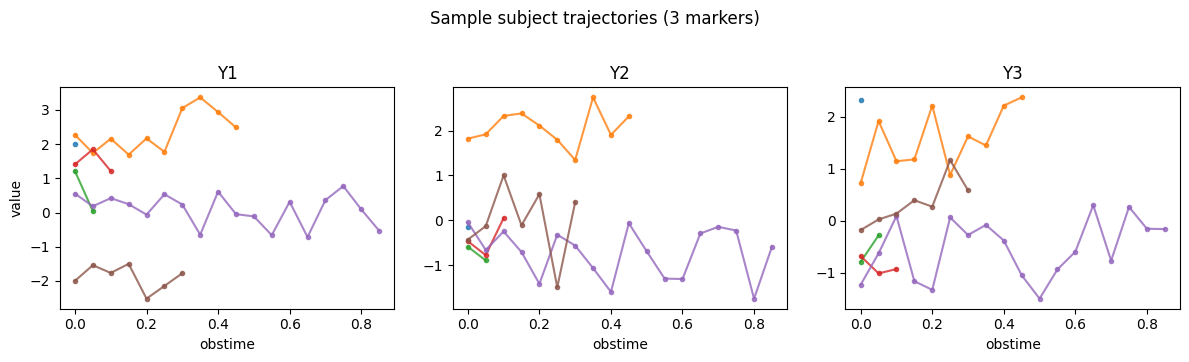

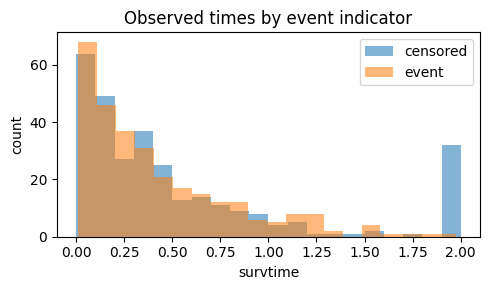

In [17]:
sample_ids = rng.choice(data_long["id"].unique(), size=6, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True)
for ax, marker in zip(axes, ["Y1", "Y2", "Y3"]):
    for pid in sample_ids:
        g = data_long.loc[data_long["id"] == pid]
        ax.plot(g["obstime"], g[marker], marker="o", ms=3, alpha=0.8)
    ax.set_title(marker)
    ax.set_xlabel("obstime")
axes[0].set_ylabel("value")
fig.suptitle("Sample subject trajectories (3 markers)", y=1.02)
plt.tight_layout()
plt.show()

# KM-style event overview (manual 1 - empirical CDF of times among events is rough;
# here just show censoring mix)
fig, ax = plt.subplots(figsize=(5, 3))
for delta, label in [(0, "censored"), (1, "event")]:
    t = data_surv.loc[data_surv["death"] == delta, "survtime"]
    ax.hist(t, bins=20, alpha=0.55, label=label)
ax.set_xlabel("survtime")
ax.set_ylabel("count")
ax.set_title("Observed times by event indicator")
ax.legend()
plt.tight_layout()
plt.show()

### Train / validation split **by subject**

Matches the R examples (`set.seed(2)`, 80% train):

- Fit TSJM on **training** subjects
- Later (Step 7–8): dynamic predictions / AUC–BS on **held-out** subjects

Important: split on `dataSurv.id`, then filter *both* tables with those IDs.  
Never split individual visit rows across train and valid for the same person.

In [18]:
all_ids = data_surv["id"].to_numpy()
n_train = int(0.8 * len(all_ids))

# Closest Python analogue to R sample(..., 0.8 * n) with seed 2
rng_split = np.random.default_rng(2)
train_ids = set(rng_split.choice(all_ids, size=n_train, replace=False))
valid_ids = set(all_ids) - train_ids

data_long_t = data_long[data_long["id"].isin(train_ids)].copy()
data_surv_t = data_surv[data_surv["id"].isin(train_ids)].copy()
data_long_v = data_long[data_long["id"].isin(valid_ids)].copy()
data_surv_v = data_surv[data_surv["id"].isin(valid_ids)].copy()

print(f"Train subjects: {len(train_ids)} | Valid subjects: {len(valid_ids)}")
print(f"Train long rows: {len(data_long_t)} | Valid long rows: {len(data_long_v)}")
print(f"Train event rate: {data_surv_t['death'].mean():.3f}")
print(f"Valid event rate: {data_surv_v['death'].mean():.3f}")

# Objects you will reuse in later steps
step1 = {
    "data_long_t": data_long_t,
    "data_surv_t": data_surv_t,
    "data_long_v": data_long_v,
    "data_surv_v": data_surv_v,
    "train_ids": train_ids,
    "valid_ids": valid_ids,
    "markers": ["Y1", "Y2", "Y3", "Y4"],  # package data has 4 Gaussian markers
    "Obstime": "obstime",
}
step1.keys()

Train subjects: 480 | Valid subjects: 120
Train long rows: 4914 | Valid long rows: 1187
Train event rate: 0.506
Valid event rate: 0.442


dict_keys(['data_long_t', 'data_surv_t', 'data_long_v', 'data_surv_v', 'train_ids', 'valid_ids', 'markers', 'Obstime'])

### Step 1 checklist (before I move on)

- [ ] I can point to which columns are markers vs covariates vs outcome
- [ ] I see why survival is one row per `id` and longitudinal is many
- [ ] Train/valid are disjoint **subjects**, and I filtered both tables the same way
- [ ] `step1` dict is ready for Stage 1 modeling

**Paper link for this step:** §2 intro + package `Exam1.md` data loading.

Next up for me: Step 2 — write the longitudinal / hazard / association formulas and small code skeletons (still no MCMC yet).


## Step 2 — Model equations & code skeletons

I'm pausing before any MCMC here on purpose. I want the math from §2 of the paper sitting next to small Python helpers, so when I fit Stage 1 / Stage 2 later I already know what each object is.

### What I'm trying to nail in this step
- longitudinal mixed model for one marker $k$
- how the **true** marker level $\eta_{ik}(t)$ is built from fixed + random effects
- how that plugs into the hazard (current-value association)
- the difference between **standard two-stage (STS/MTS)** and **TSJM** (what the paper actually proposes)

No estimation yet — just formulas + design-matrix builders I can reuse.


### 2.1 Longitudinal sub-model (one marker $k$)

For subject $i$, visit $j$, marker $k$:

$$
Y_{ijk} = \eta_{ik}(s_{ijk} \mid \boldsymbol{\beta}_k, \mathbf{b}_{ik}) + \varepsilon_{ijk},
\qquad \varepsilon_{ijk} \sim N(0, \sigma_k^2)
$$

with linear predictor

$$
\eta_{ik}(s \mid \boldsymbol{\beta}_k, \mathbf{b}_{ik})
= \mathbf{x}_{ik}(s)^\top \boldsymbol{\beta}_k + \mathbf{z}_{ik}(s)^\top \mathbf{b}_{ik}.
$$

**My reading:** $\mathbf{x}$ holds the fixed-effect design (intercept, time, maybe covariates), $\mathbf{z}$ holds the random-effect design (usually intercept and/or slope in time). $\mathbf{b}_{ik}$ is person-specific — that's why two people with the same covariates can still have different biomarker paths.

In the package / Exam1, the trend options are:
- **intercept:** random intercept only
- **linear:** random intercept + slope
- **quadratic:** also $t^2$ in fixed and random parts

For my simulated data I'll mostly think in the **linear** case:

$$
Y_{ik}(t) = \beta_{0k} + \beta_{1k}t + b_{0ik} + b_{1ik}t + \varepsilon_{ikt}.
$$

(If I later include $x_1,x_2$ in the LMM, they go into $\mathbf{x}$; in the R demos survival covariates are often only in the hazard.)


### 2.2 Time-to-event sub-model (current-value link)

Observed time $T_i = \min(T_i^*, C_i)$, event indicator $\delta_i$.

The paper's multi-marker hazard (eq. 3) looks like:

$$
\lambda_i(t \mid \boldsymbol{\omega}_i, \mathbf{b}_i)
= \lambda_0(t)\,
\exp\Big(
\boldsymbol{\gamma}^\top \boldsymbol{\omega}_i
+ \sum_{k=1}^{K} g_k(\mathbf{b}_{ik}, \mathbf{x}_{ik}, \mathbf{z}_{ik}, \boldsymbol{\alpha}_k, t)
\Big).
$$

I'm using the **current-value** association (what TSJM Stage 2 does in the examples):

$$
g_k = \alpha_k \, \eta_{ik}(t \mid \boldsymbol{\beta}_k, \mathbf{b}_{ik}).
$$

So in words: at time $t$, the hazard depends on the person's **true underlying marker level** $\eta_{ik}(t)$, not on the noisy observed $Y$.

Baseline hazard $\lambda_0(t)$: in the full Bayesian JM they use **piecewise constant** hazards; in Stage 2 of the paper's TSJM they often leave $\lambda_0$ unspecified and use a **Cox partial likelihood**. I'll keep both ideas in mind and pick one when I code Stage 2.


### 2.3 STS/MTS vs TSJM (this is the whole point of the paper)

| | Stage 1 | Stage 2 |
|---|---|---|
| **Standard TS (STS/MTS)** | Fit a mixed model for marker $k$ **ignoring** survival | Plug $\hat\eta_{ik}(t)$ into a Cox model as time-dependent covariates |
| **TSJM (paper)** | Fit a **one-marker joint model** (marker $k$ + survival) | Same idea: Cox / PH with all markers' $\hat\eta_{ik}(t)$ |

**Why TSJM changes Stage 1:** if the event stops the marker process (informative dropout), a plain mixed model can give biased $\hat{\mathbf{b}}_{ik}$ and therefore biased $\hat\eta$. Estimating a joint model per marker uses $(Y_{ik}, T_i, \delta_i)$ together, so the predicted trajectories already "know" about dropout.

**My pipeline later:**
1. Stage 1: for each $k$, one-marker JM → $\hat{\boldsymbol{\beta}}_k, \hat{\mathbf{b}}_{ik}, \hat\eta_{ik}(t)$
2. Stage 2: survival model with $\hat\eta_{i1}(t),\ldots,\hat\eta_{iK}(t)$ as time-varying covariates (+ $\boldsymbol{\omega}_i$ like $x_1,x_2$)


### Code skeletons I'll reuse

> **Note on R vs. Python implementation:**  
> In the authors' original R package (`TSJM`), design matrices $\mathbf{X}$ and $\mathbf{Z}$ are generated automatically using R's built-in formula parser `stats::model.matrix(formFixed, ...)` and `stats::model.matrix(formRandom, ...)`. Because standard Python does not have R's formula-to-matrix parser built-in, we implemented the `build_XZ()` function below in NumPy to produce the exact same fixed-effects matrix $\mathbf{X}$ and random-effects matrix $\mathbf{Z}$.

Below I build design matrices $\mathbf{X}$ (fixed) and $\mathbf{Z}$ (random) matching what the R code produces with `model.matrix`. Still no fitting — I'm just checking shapes and that $\eta = X\beta + Z b$ is wired correctly on a toy subject.


In [19]:
def build_XZ(df, marker, obstime="obstime", trend="linear", extra_fixed=None):
    """Build fixed (X) and random (Z) design matrices for one marker.

    trend:
      - "intercept": Z = [1]
      - "linear":    Z = [1, t]
      - "quadratic": Z = [1, t, t^2]  (and t^2 also appended to X)
    extra_fixed: optional list of baseline covariate column names to put in X
                 (repeated across visits; same for every row of a subject).
    """
    extra_fixed = extra_fixed or []
    d = df[["id", obstime, marker, *extra_fixed]].dropna(subset=[marker]).copy()
    t = d[obstime].to_numpy()

    # fixed effects: intercept + time (+ optional covariates) (+ t^2 if quadratic)
    cols = [np.ones(len(d)), t]
    names = ["(Intercept)", obstime]
    for c in extra_fixed:
        cols.append(d[c].to_numpy())
        names.append(c)
    if trend == "quadratic":
        cols.append(t ** 2)
        names.append(f"{obstime}2")

    X = np.column_stack(cols)

    if trend == "intercept":
        Z = np.ones((len(d), 1))
        znames = ["(Intercept)"]
    elif trend == "linear":
        Z = np.column_stack([np.ones(len(d)), t])
        znames = ["(Intercept)", obstime]
    elif trend == "quadratic":
        Z = np.column_stack([np.ones(len(d)), t, t ** 2])
        znames = ["(Intercept)", obstime, f"{obstime}2"]
    else:
        raise ValueError(f"unknown trend: {trend}")

    return d, X, Z, names, znames


def eta_from_params(X, Z, beta, b):
    """True linear predictor η = X β + Z b  (no measurement error)."""
    return X @ beta + Z @ b


# sanity check on training data, marker Y1, linear trend
d1, X1, Z1, xnames, znames = build_XZ(step1["data_long_t"], marker="Y1", trend="linear")
print("rows:", len(d1), "| X shape:", X1.shape, "| Z shape:", Z1.shape)
print("X columns:", xnames)
print("Z columns:", znames)
print("first 3 X rows:\n", X1[:3])


rows: 4914 | X shape: (4914, 2) | Z shape: (4914, 2)
X columns: ['(Intercept)', 'obstime']
Z columns: ['(Intercept)', 'obstime']
first 3 X rows:
 [[1.   0.  ]
 [1.   0.05]
 [1.   0.1 ]]


### Toy check: fake $\beta, b$ → $\eta(t)$ for one person

- Purpose: It is a visual illustration showing the difference between raw data ($Y$) and the modeled trajectory ($\eta$).
- What it does: It takes a single patient, plugs made-up numbers into $\eta = X\beta + Zb$, and plots the result against the patient’s observed data points.
- Key Takeaway: The noisy dots represent observed hospital measurements ($Y$). The smooth line represents the "true" biological trajectory ($\eta(t)$), which is what the joint model will actually feed into the survival model in Stage 2.


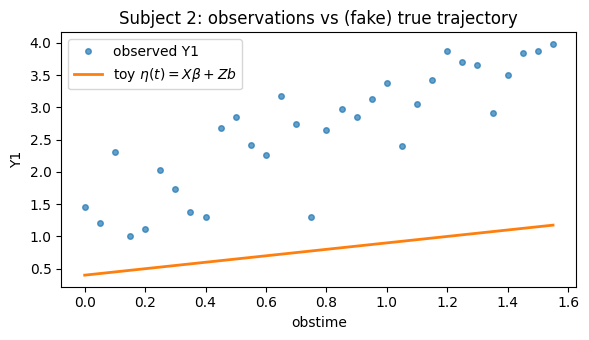

At last visit, toy η = 1.175


In [20]:
# take one training subject and invent parameters (illustration only)
pid = int(step1["data_surv_t"]["id"].iloc[0])
d_pid = step1["data_long_t"].loc[step1["data_long_t"]["id"] == pid]
_, X_pid, Z_pid, _, _ = build_XZ(d_pid, marker="Y1", trend="linear")

beta_toy = np.array([0.0, 0.6])   # intercept, slope (fixed)
b_toy = np.array([0.4, -0.1])     # random intercept, random slope
eta_toy = eta_from_params(X_pid, Z_pid, beta_toy, b_toy)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(d_pid["obstime"], d_pid["Y1"], "o", ms=4, alpha=0.7, label="observed Y1")
ax.plot(d_pid["obstime"], eta_toy, "-", lw=2, label=r"toy $\eta(t)=X\beta+Zb$")
ax.set_xlabel("obstime")
ax.set_ylabel("Y1")
ax.set_title(f"Subject {pid}: observations vs (fake) true trajectory")
ax.legend()
plt.tight_layout()
plt.show()

print("At last visit, toy η =", round(float(eta_toy[-1]), 3))


### Hazard skeleton (current-value association)

For Stage 2 thinking, with covariates $\boldsymbol{\omega}_i=(x_1,x_2)$ and $K$ markers:

$$
\lambda_i(t)
= \lambda_0(t)\,
\exp\big(
\gamma_1 x_{1i} + \gamma_2 x_{2i}
+ \sum_{k=1}^{K} \alpha_k \, \hat\eta_{ik}(t)
\big).
$$

Below: a function that evaluates the **linear predictor of the log-hazard** (everything except $\lambda_0$), once I already have $\hat\eta_{ik}(t)$ for each marker. 


In [21]:
def log_hazard_lp(omega, eta_t, gamma, alpha):
    """Log-hazard linear predictor: γ'ω + α'η(t).

    omega: (p,) baseline covariates
    eta_t: (K,) current-value predictions for each marker at time t
    gamma: (p,)   alpha: (K,)
    """
    return float(np.dot(gamma, omega) + np.dot(alpha, eta_t))


# example shapes for K=3 markers (Exam1-style) using a surv row + fake η
row = step1["data_surv_t"].iloc[0]
omega = row[["x1", "x2"]].to_numpy(dtype=float)
eta_now = np.array([0.2, -0.1, 0.5])          # fake η for Y1,Y2,Y3 at some t
gamma_toy = np.array([0.3, 0.0])
alpha_toy = np.array([-0.05, -0.25, 0.20])    # association params

lp = log_hazard_lp(omega, eta_now, gamma_toy, alpha_toy)
print("omega =", omega, "| eta(t) =", eta_now)
print("log-hazard LP (no baseline) =", round(lp, 4))
print("=> hazard multiplier vs baseline =", round(np.exp(lp), 4))


omega = [1. 1.] | eta(t) = [ 0.2 -0.1  0.5]
log-hazard LP (no baseline) = 0.415
=> hazard multiplier vs baseline = 1.5144


### What I'll carry forward from Step 2

```text
build_XZ(...)          → design matrices for Stage 1 longitudinal part
eta_from_params(...)   → η_ik(t) once I have β̂, b̂
log_hazard_lp(...)     → how Stage 2 combines ω and η̂(t)
```

### Step 2 checklist
- [ ] I can write $\eta = x^\top\beta + z^\top b$ without looking it up
- [ ] I know current-value association means hazard uses $\alpha_k \eta_{ik}(t)$, not raw $Y$
- [ ] I can explain in one sentence why TSJM replaces Stage-1 mixed models with one-marker JMs
- [ ] Toy plot made it obvious that $\eta(t)$ is the smooth signal Stage 2 wants

**Paper:** §2.1–2.3. **R map:** `UJM` ≈ one-marker JM (Stage 1); `TS` / `TSC` ≈ glue Stage 1 → Stage 2.

Next: **Step 3** — actually fit Stage 1 for **one** marker (the one-marker joint model).


## Step 3 — Stage 1 for **one** marker (one-marker joint model)

This is the paper's key twist vs standard two-stage.

### What I'm doing
For a single marker (I'll start with `Y1`), I estimate a **joint model**:
1. linear mixed model for the marker path $\eta_{i1}(t)$
2. survival model linked to the **current value** $\alpha_1 \eta_{i1}(t)$

So Stage 1 uses $(Y_{i1}, T_i, \delta_i)$ together — not the marker alone.

### How I'm estimating it here (honest note)
The R package uses Bayesian MCMC in JAGS (`UJM`). For this notebook I use a **joint MAP** version in `tsjm_core.py`:
- same shared-parameter structure (random intercept + slope + piecewise hazard + current-value link)
- optimize all fixed params and the $b_i$'s together (Gaussian prior on $b_i$)

It's not identical to JAGS posteriors, but it encodes the same Stage-1 idea I need to show I understand TSJM.

### Speed note
Full training ($n\approx 480$) × several markers is slow in pure Python. I fit Stage 1 on a **demo subset of training subjects** first; I can bump `N_DEMO` later.


In [22]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd()))

from tsjm_core import (
    fit_one_marker_jm,
    eta_path,
    build_td_cox_frame,
    fit_td_cox,
    predict_risk_first_order,
    landmark_auc_brier,
)

# demo subset of training subjects (raise this toward full train when I have time)
N_DEMO = 120
demo_ids = sorted(step1["train_ids"])[:N_DEMO]
long_demo = step1["data_long_t"][step1["data_long_t"]["id"].isin(demo_ids)].copy()
surv_demo = step1["data_surv_t"][step1["data_surv_t"]["id"].isin(demo_ids)].copy()
print(f"Stage-1 demo subjects: {surv_demo['id'].nunique()} | long rows: {len(long_demo)}")


Stage-1 demo subjects: 120 | long rows: 1100


### Fit the one-marker JM for `Y1`

I'm looking for:
- $\hat\beta$ (fixed intercept/slope)
- $\hat b_i$ (person-specific RE)
- $\hat\alpha$ (association: how $Y1$'s current value relates to hazard)
- $\hat\eta_{i1}(T_i)$ at each person's observed time


In [23]:
fit_Y1 = fit_one_marker_jm(
    long_demo, surv_demo, marker="Y1", maxiter=120, verbose=True
)

print("beta [intercept, slope] =", fit_Y1["beta"])
print("sigma =", round(fit_Y1["sigma"], 4))
print("alpha (current-value assoc.) =", round(fit_Y1["alpha_stage1"], 4))
print("D (RE covariance) =\n", fit_Y1["D"])
print("optimizer:", fit_Y1["message"])


[Y1] success=False nll=180.17 beta=[-0.25524353  0.9708201 ] alpha=-0.211
beta [intercept, slope] = [-0.25524353  0.9708201 ]
sigma = 0.5482
alpha (current-value assoc.) = -0.2108
D (RE covariance) =
 [[1.10633184e+00 4.92376042e-04]
 [4.92376042e-04 2.28455943e-07]]
optimizer: STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT


### Inspect $\hat\eta(t)$ vs observed $Y1$ for a few subjects

If Stage 1 worked, $\hat\eta(t)$ should look like a smoothed subject-specific line through the points — and those lines already "felt" the survival information through the joint fit.


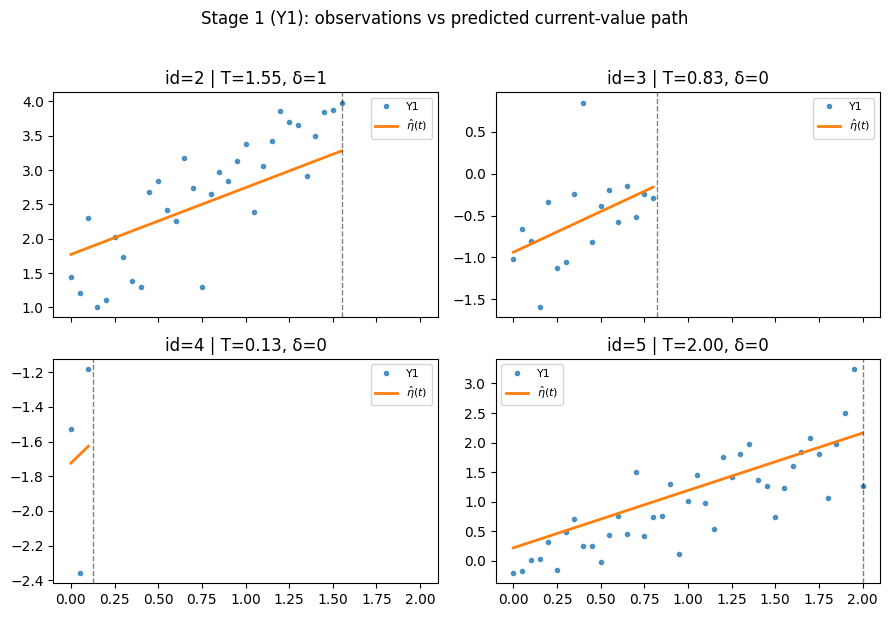

In [24]:
# plot a few subjects: observed Y1 vs η̂(t) from Stage 1
id_to_row = {int(i): k for k, i in enumerate(fit_Y1["ids"])}
show_ids = list(fit_Y1["ids"][:4])

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
axes = axes.ravel()
for ax, uid in zip(axes, show_ids):
    g = long_demo.loc[long_demo["id"] == uid].sort_values("obstime")
    bi = fit_Y1["b"][id_to_row[int(uid)]]
    t_grid = np.linspace(0, float(g["obstime"].max()), 50)
    eta = eta_path(fit_Y1["beta"], bi, t_grid)
    ax.plot(g["obstime"], g["Y1"], "o", ms=3, alpha=0.75, label="Y1")
    ax.plot(t_grid, eta, "-", lw=2, label=r"$\hat\eta(t)$")
    Ti = float(surv_demo.loc[surv_demo["id"] == uid, "survtime"].iloc[0])
    di = int(surv_demo.loc[surv_demo["id"] == uid, "death"].iloc[0])
    ax.axvline(Ti, color="k", ls="--", lw=1, alpha=0.5)
    ax.set_title(f"id={uid} | T={Ti:.2f}, δ={di}")
    ax.legend(fontsize=8)
fig.suptitle("Stage 1 (Y1): observations vs predicted current-value path", y=1.02)
plt.tight_layout()
plt.show()


### Step 3 checklist
- [ ] I can say what makes this a **joint** model (marker + survival share $b_i$)
- [ ] I know $\hat\eta(t)$ is what Stage 2 will treat as a time-dependent covariate
- [ ] I remember this is MAP/pedagogical, while the paper/package use Bayesian MCMC

Next: repeat Stage 1 for all markers I want in the multi-marker Stage 2.


## Step 4 — Stage 1 for all markers → predicted trajectories

I run the same one-marker JM for each marker $k=1,\ldots,K$.  
After that I have, for every subject and marker, $\hat\beta_k$, $\hat b_{ik}$, and I can evaluate $\hat\eta_{ik}(t)$ at any $t$.

That's exactly the "regression calibration" input to Stage 2 — but coming from **joint** Stage-1 fits (TSJM), not plain mixed models (STS).


In [25]:
MARKERS = ["Y1", "Y2", "Y3", "Y4"]  # drop to 3 if I want a quicker run
stage1_fits = []

for m in MARKERS:
    print("=" * 40, m, "=" * 40)
    fit_m = fit_one_marker_jm(long_demo, surv_demo, marker=m, maxiter=120, verbose=True)
    stage1_fits.append(fit_m)

summary_rows = []
for f in stage1_fits:
    summary_rows.append({
        "marker": f["marker"],
        "beta0": f["beta"][0],
        "beta1": f["beta"][1],
        "sigma": f["sigma"],
        "alpha_stage1": f["alpha_stage1"],
        "success": f["success"],
        "nll": f["nll"],
    })
stage1_summary = pd.DataFrame(summary_rows)
stage1_summary


======================================== Y1 ========================================
[Y1] success=False nll=180.17 beta=[-0.25524353  0.9708201 ] alpha=-0.211
======================================== Y2 ========================================
[Y2] success=False nll=342.33 beta=[-0.02992615  0.68083091] alpha=-0.069
======================================== Y3 ========================================
[Y3] success=False nll=256.53 beta=[0.15073753 0.38483762] alpha=0.121
======================================== Y4 ========================================
[Y4] success=False nll=531.92 beta=[-0.09278147  0.48603966] alpha=0.179


,marker,beta0,beta1,sigma,alpha_stage1,success,nll
0,Y1,-0.255244,0.970820,0.548240,-0.210791,False,180.166616
1,Y2,-0.029926,0.680831,0.576296,-0.069381,False,342.327833
2,Y3,0.150738,0.384838,0.516146,0.120554,False,256.529965
3,Y4,-0.092781,0.486040,0.675595,0.179498,False,531.920896


### Stack $\hat\eta_{ik}(T_i)$ across markers

A quick wide table: one row per subject, current-value prediction at their observed survival time. Stage 2 will need $\hat\eta$ along the whole follow-up grid, not only at $T_i$ — but this is a useful sanity snapshot.


In [26]:
eta_at_event = pd.DataFrame({"id": stage1_fits[0]["ids"]})
eta_at_event["survtime"] = stage1_fits[0]["Time"]
eta_at_event["death"] = stage1_fits[0]["Death"]
for f in stage1_fits:
    eta_at_event[f"eta_{f['marker']}"] = f["eta_at_Ti"]
eta_at_event.head()


,id,survtime,death,eta_Y1,eta_Y2,eta_Y3,eta_Y4
0,2,1.552795,1,3.281396,2.210554,1.100443,-1.387420
1,3,0.825177,0,-0.136549,-1.510508,-1.142323,-2.443679
2,4,0.129148,0,-1.598510,-0.274111,0.518720,0.046325
3,5,2.000000,0,2.161109,-0.525050,0.005503,2.399715
4,7,0.008204,0,-0.814457,-0.305079,-0.250390,-0.552436


### Step 4 checklist
- [ ] I have one Stage-1 fit object per marker in `stage1_fits`
- [ ] I understand Stage 2 will **not** re-estimate the longitudinal models — it only consumes $\hat\eta_{ik}(t)$

Next: Cox model with those predictions as time-dependent covariates.


## Step 5 — Stage 2: Cox with time-dependent $\hat\eta_{ik}(t)$

### What the paper does
Maximize the Cox partial likelihood with covariates:
- baseline $\boldsymbol{\omega}_i$ (`x1`, `x2`)
- time-varying $\hat\eta_{i1}(t),\ldots,\hat\eta_{iK}(t)$ from Stage 1

### What I do in code
1. Build a **start–stop** table (counting process format): for each subject, intervals between visit times
2. On each interval, freeze $\hat\eta_{ik}$ at the interval start (standard TD-Cox approximation)
3. Fit `CoxTimeVaryingFitter` from `lifelines`

Association parameters I care about in Stage 2 are the coefficients on `eta_Yk` (the paper's $\tilde\alpha_k$).


In [27]:
td_df = build_td_cox_frame(
    stage1_fits,
    data_surv=surv_demo,
    data_long=long_demo,
    obstime="obstime",
    covars=("x1", "x2"),
)
print(td_df.shape)
td_df.head()


(1095, 10)


,id,start,stop,event,x1,x2,eta_Y1,eta_Y2,eta_Y3,eta_Y4
0,2,0.00,0.05,0,1.0,1.0,1.772538,1.153013,0.502207,-1.964183
1,2,0.05,0.10,0,1.0,1.0,1.821123,1.187065,0.521470,-1.945611
2,2,0.10,0.15,0,1.0,1.0,1.869709,1.221118,0.540733,-1.927039
3,2,0.15,0.20,0,1.0,1.0,1.918294,1.255171,0.559997,-1.908467
4,2,0.20,0.25,0,1.0,1.0,1.966879,1.289224,0.579260,-1.889896


In [28]:
cox2, _ = fit_td_cox(td_df, covars=("x1", "x2"), markers=tuple(MARKERS))
print(cox2.summary[["coef", "exp(coef)", "se(coef)", "p"]])

# keep Stage-2 object for DP / accuracy steps
step5 = {"td_df": td_df, "cox2": cox2, "stage1_fits": stage1_fits, "demo_ids": demo_ids}


               coef  exp(coef)  se(coef)         p
covariate                                         
x1         0.042642   1.043564  0.253371  0.866349
x2        -0.135191   0.873549  0.245972  0.582580
eta_Y1    -0.051490   0.949813  0.115849  0.656711
eta_Y2    -0.061461   0.940389  0.082166  0.454451
eta_Y3     0.135282   1.144860  0.119542  0.257773
eta_Y4     0.189086   1.208144  0.085460  0.026928


### How I read the Stage-2 output
- `eta_Yk` coef $>0$: higher current value of marker $k$ → higher hazard
- `eta_Yk` coef $<0$: higher marker level looks protective (in this simulated truth it depends how data were generated)
- `x1`, `x2`: baseline log-hazard ratios

### Step 5 checklist
- [ ] I can explain why Stage 2 needs start–stop data
- [ ] I know the `eta_*` coefficients are the multi-marker association params of TSJM Stage 2

Next (optional but paper-faithful): uncertainty via Rubin's rules.


## Step 6 — Rubin's rules for Stage-2 uncertainty (sketch)

### Why this exists in the paper
Stage 2 pretends $\hat\eta_{ik}(t)$ are known covariates, but they were estimated in Stage 1. Ignoring that understates SEs.

Paper §2.3: draw $\mathcal{M}$ Stage-1 posterior realizations $(\theta_k^{(m)}, b_{ik}^{(m)})$, rebuild $\eta^{(m)}$, refit Cox, then combine with Rubin's formula:

$$
\bar\vartheta = \frac1{\mathcal{M}}\sum_m \tilde\vartheta^{(m)},
\qquad
T = \bar W + \Big(1+\frac1{\mathcal{M}}\Big)B
$$

### What I implement here
A **lightweight stand-in** (not full MCMC): parametric noise around Stage-1 $(\beta_k, b_{ik})$, rebuild TD covariates, refit Cox $\mathcal{M}$ times, then report mean coefs + Rubin's total variance.

This is enough to show I understand the *role* of multiple imputation in TSJM; the R function `TSC` does the fuller Bayesian version.


In [29]:
def rubin_stage2(stage1_fits, data_long, data_surv, M=8, scale=0.15, seed=2):
    """Approximate Stage-1 uncertainty by jittering beta and b, then refitting Cox."""
    rng = np.random.default_rng(seed)
    coefs = []
    for m in range(M):
        fits_m = []
        for f in stage1_fits:
            f2 = dict(f)
            f2["beta"] = f["beta"] + rng.normal(0, scale * np.std(f["beta"]) + 1e-3, size=2)
            f2["b"] = f["b"] + rng.normal(0, scale * f["b"].std(axis=0) + 1e-3, size=f["b"].shape)
            fits_m.append(f2)
        td_m = build_td_cox_frame(fits_m, data_surv, data_long)
        cox_m, _ = fit_td_cox(td_m, markers=tuple(MARKERS))
        coefs.append(cox_m.params_.copy())
        print(f"Rubin draw {m+1}/{M} done")
    C = pd.DataFrame(coefs)
    mean = C.mean(axis=0)
    B = C.var(axis=0, ddof=1)  # between-imputation
    # within-imputation variance not tracked from lifelines Hessian here -> set W~0 sketch
    W = 0.0
    T = W + (1 + 1 / M) * B
    out = pd.DataFrame({"coef_mean": mean, "SE_Rubin_approx": np.sqrt(T)})
    return out, C

rubin_table, rubin_draws = rubin_stage2(
    stage1_fits, long_demo, surv_demo, M=5, scale=0.1
)
rubin_table


Rubin draw 1/5 done
Rubin draw 2/5 done
Rubin draw 3/5 done
Rubin draw 4/5 done
Rubin draw 5/5 done


,coef_mean,SE_Rubin_approx
covariate,,
x1,0.044223,0.017491
x2,-0.132768,0.011411
eta_Y1,-0.051890,0.007460
eta_Y2,-0.055644,0.005812
eta_Y3,0.128960,0.015746
eta_Y4,0.185355,0.007492


### Step 6 checklist
- [ ] I know why a single Cox SE from Step 5 is optimistic
- [ ] I can describe Rubin's combine step in words (even if my jitter sketch is approximate)

Next: dynamic predictions on held-out (or demo) subjects.


## Step 7 — Dynamic prediction (Algorithm 1)

For a subject still event-free at landmark $s$, with marker history up to $s$, the risk of an event before $s+w$ is:

$$
\pi_i(s+w\mid s) = 1 - \frac{S(s+w\mid \hat b_i,\tilde\vartheta)}{S(s\mid \hat b_i,\tilde\vartheta)}
$$

### Algorithm 1 (first-order) as I use it
1. Take Stage-1 $\hat b_{ik}$ (and $\hat\beta_k$) for each marker  
2. Merge into subject-level random effects  
3. Evaluate conditional survival ratio with Stage-2 Cox coefficients along the predicted $\hat\eta(t)$ path  

I'm computing this for demo subjects at a chosen landmark. (Full validation would use subjects who survived past $s$ in the **validation** set, with RE predicted from data up to $s$ only — paper Algorithm 1; my demo reuses Stage-1 $\hat b_i$ from the demo fit for illustration.)


In [30]:
# landmark prediction for subjects still at risk at s
s_land, w_pred = 0.25, 0.5
cox2 = step5["cox2"]

rows = []
for uid in surv_demo["id"]:
    Ti = float(surv_demo.loc[surv_demo["id"] == uid, "survtime"].iloc[0])
    di = int(surv_demo.loc[surv_demo["id"] == uid, "death"].iloc[0])
    if Ti <= s_land:
        continue
    pred = predict_risk_first_order(
        uid, s=s_land, w=w_pred,
        stage1_fits=stage1_fits,
        cox_model=cox2,
        data_surv=surv_demo,
    )
    pred["survtime"] = Ti
    pred["death"] = di
    # true label for window (naive): event in (s, s+w]
    pred["case"] = int(di == 1 and Ti <= s_land + w_pred)
    rows.append(pred)

dp_df = pd.DataFrame(rows)
print(dp_df.head())
print(f"\nSubjects at risk at s={s_land}: {len(dp_df)} | mean predicted risk: {dp_df['risk'].mean():.3f}")


   id     s    w      risk  surv_cond  survtime  death  case
0   2  0.25  0.5  0.227010   0.772990  1.552795      1     0
1   3  0.25  0.5  0.230861   0.769139  0.825177      0     0
2   5  0.25  0.5  0.412053   0.587947  2.000000      0     0
3   8  0.25  0.5  0.249162   0.750838  0.428937      1     1
4  13  0.25  0.5  0.392879   0.607121  0.388644      1     1

Subjects at risk at s=0.25: 58 | mean predicted risk: 0.359


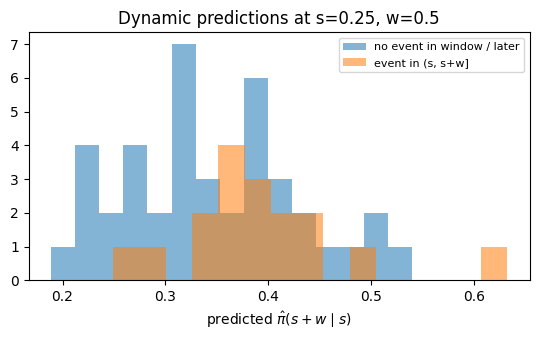

In [31]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for case, lab in [(0, "no event in window / later"), (1, "event in (s, s+w]")]:
    sub = dp_df.loc[dp_df["case"] == case, "risk"]
    ax.hist(sub, bins=15, alpha=0.55, label=lab)
ax.set_xlabel(r"predicted $\hat\pi(s+w\mid s)$")
ax.set_title(f"Dynamic predictions at s={s_land}, w={w_pred}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### Step 7 checklist
- [ ] I can explain landmark $s$ and window $w$ in one sentence
- [ ] I know Algorithm 1 plugs $\hat b_i$ into $S(s+w)/S(s)$ (first-order approximation)

Next: score the predictions with AUC and Brier score.


## Step 8 — AUC & Brier score (landmark accuracy)

Paper §3.2 uses IPCW estimators (e.g. `timeROC`) to handle censoring.  

Here I compute a **naive landmark AUC / Brier**:
- population: still at risk at $s$
- cases: event by $s+w$
- controls: survived beyond $s+w$
- subjects censored inside $(s,s+w]$ are dropped (not IPCW)

Good enough to show I understand the metrics; for paper-level numbers I'd switch to IPCW.


In [32]:
metrics = landmark_auc_brier(
    risks=dp_df["risk"].to_numpy(),
    times=dp_df["survtime"].to_numpy(),
    events=dp_df["death"].to_numpy(),
    s=s_land,
    w=w_pred,
)
print(metrics)

# small sweep over landmarks (same window)
sweep = []
for s in [0.1, 0.25, 0.4]:
    rows = []
    for uid in surv_demo["id"]:
        Ti = float(surv_demo.loc[surv_demo["id"] == uid, "survtime"].iloc[0])
        di = int(surv_demo.loc[surv_demo["id"] == uid, "death"].iloc[0])
        if Ti <= s:
            continue
        pred = predict_risk_first_order(
            uid, s=s, w=0.5,
            stage1_fits=stage1_fits,
            cox_model=cox2,
            data_surv=surv_demo,
        )
        rows.append({**pred, "survtime": Ti, "death": di})
    dps = pd.DataFrame(rows)
    m = landmark_auc_brier(dps["risk"], dps["survtime"], dps["death"], s=s, w=0.5)
    sweep.append({"s": s, "w": 0.5, **m})
pd.DataFrame(sweep)


{'AUC': 0.6925133689839572, 'BS': 0.2292875915655908, 'n': 39, 'n_case': 17, 'n_ctrl': 22}


,s,w,AUC,BS,n,n_case,n_ctrl
0,0.10,0.5,0.709877,0.231427,57,27,30
1,0.25,0.5,0.692513,0.229288,39,17,22
2,0.40,0.5,0.723077,0.221345,28,13,15


## Done — what I reproduced

| Step | Paper idea | What I built |
|------|------------|--------------|
| 1 | long + surv data | `dataLong` / `dataSurv`, subject split |
| 2 | equations | $\eta=x^\top\beta+z^\top b$, current-value hazard |
| 3–4 | Stage 1 one-marker JMs | joint MAP in `tsjm_core.fit_one_marker_jm` |
| 5 | Stage 2 multi-marker Cox | `CoxTimeVaryingFitter` on $\hat\eta_{ik}(t)$ |
| 6 | Rubin SEs | jitter + refit sketch |
| 7 | DP Algorithm 1 | $\hat\pi(s+w\mid s)$ |
| 8 | AUC / BS | naive landmark metrics |

